<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Measured at sea, forecast by ECMWF 🌊🇬🇷
### Mediterranean wave buoys (Copernicus Marine) × the ECMWF wave model (open data) · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/buoys_vs_waves.ipynb)

<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/greece/buoys_vs_waves.gif" width="720"/>

*A month of waves: the map is the ECMWF wave model, each dot a buoy filled with what it measured. Where a dot disappears,
the two agree. The chart follows the HCMR buoy off Heraklion, Crete.*

The land-station notebooks put HNMS stations next to the ECMWF forecast. This one does the same at sea. Buoys moored
in the Mediterranean measure the waves every 30 minutes to 3 hours and send them to the **Copernicus Marine Service**,
which publishes them openly. ECMWF's **wave model** forecasts the same sea state worldwide, also as open data.

| Data | What this notebook uses | Licence |
|---|---|---|
| Wave buoys, [Copernicus Marine In Situ TAC](https://data.marine.copernicus.eu/product/INSITU_MED_PHYBGCWAV_DISCRETE_MYNRT_013_035/services), Mediterranean product (assembled by HCMR) | significant wave height, highest wave, peak period, direction; the last few days | [Copernicus Marine licence](https://marine.copernicus.eu/user-corner/service-commitments-and-licence), free |
| [ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data): wave model (HRES-WAM), 0.25° | significant wave height, first 9 hours of each 00 and 12 UTC run | CC BY 4.0, © ECMWF |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools, with pandas and cartopy.

*Press **Runtime → Run all**. It takes about five minutes.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a minute or two.
%pip install -q "earthkit-data[ecmwf-opendata]" ecmwf-opendata cartopy netCDF4

## 1 · Settings, and every wave buoy in the Mediterranean

In [2]:
# ---- settings: change these and run again ------------------------------------------------------------------
DAYS = 7               # days to look at, ending with the newest buoy data (Copernicus keeps the last ~30 days ready)
FOCUS = "HERAKLION"    # the buoy for the timelines: any code from the table in section 1 (e.g. "6100211", "6101031")
NEAR = 0.5             # metres: "the model agrees" when it is this close to the buoy
# ---------------------------------------------------------------------------------------------------------------

import pyproj                     # import before earthkit.data (avoids a crash at exit)
import os, re, datetime as dt, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, requests, xarray as xr
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm
import cartopy.crs as ccrs, cartopy.feature as cfeature
import earthkit.data as ekd
from ecmwf.opendata import Client
warnings.filterwarnings("ignore")

S3 = "https://s3.waw3-1.cloudferro.com/mdl-native-03"
MED = "native/INSITU_MED_PHYBGCWAV_DISCRETE_MYNRT_013_035/cmems_obs-ins_med_phybgcwav_mynrt_na_irr_202311"
BOX = dict(north=46.5, south=30.0, west=-6.5, east=37.0)
GREEK = dict(north=41.5, south=34.0, west=19.0, east=29.5)
NAVY, ORANGE, RED, GREY = "#1d2230", "#b5580b", "#c0392b", "#9a9a9a"
LEVELS = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4, 5, 6]          # wave height colour steps, map and dots alike
CMAP = plt.get_cmap("YlGnBu", len(LEVELS) - 1).with_extremes(over="#2b0a3d")   # above 6 m: dark purple
NORM = BoundaryNorm(LEVELS, CMAP.N, extend="neither")

In [3]:
# every moored buoy that has ever reported waves to the Copernicus Mediterranean product (the catalogue is a text file)
WAVE = {"VHM0", "VGHS", "VAVH"}                       # three names for significant wave height, by operator
cols = ["code", "created", "updated", "wmo", "source", "operator", "edmo", "params", "lat", "lon", "last"]
cat = pd.read_csv(f"{S3}/{MED}/index_platform.txt", comment="#", names=cols, dtype=str, skipinitialspace=True)
cat = cat[cat.source.fillna("").str.contains("_TS_MO_") & cat.params.fillna("").str.split().apply(lambda p: bool(WAVE & set(p)))].copy()
cat[["lat", "lon"]] = cat[["lat", "lon"]].astype(float)
cat["last"] = pd.to_datetime(cat["last"], utc=True).dt.tz_localize(None)
cat["operator"] = cat.operator.str.split(";").str[0]
cat["reporting"] = cat["last"] >= cat["last"].max() - pd.Timedelta(days=7)
cat["greek_seas"] = cat.lat.between(GREEK["south"], GREEK["north"]) & cat.lon.between(GREEK["west"], GREEK["east"])
print(f"{len(cat)} wave buoys ever, {cat.reporting.sum()} reporting this week; "
      f"Greek seas: {cat.greek_seas.sum()} ever, {(cat.greek_seas & cat.reporting).sum()} reporting")
cat[cat.greek_seas][["code", "operator", "lat", "lon", "last", "reporting"]].sort_values("last")

106 wave buoys ever, 50 reporting this week; Greek seas: 14 ever, 1 reporting


,code,operator,lat,lon,last,reporting
4095,KALAM,Hellenic Centre for Marine Research - Institut...,36.971000,22.094000,2011-02-26 06:00:00,False
4606,SANTO,Hellenic Centre for Marine Research - Institut...,36.262000,25.501000,2011-03-03 15:00:00,False
5132,ZAKYN,Hellenic Centre for Marine Research - Institut...,37.956000,20.604000,2012-01-23 09:00:00,False
4777,SKYRO,Hellenic Centre for Marine Research - Institut...,39.113000,24.464000,2012-07-18 15:00:00,False
4150,LESVO,Hellenic Centre for Marine Research - Institut...,39.156000,25.807000,2012-07-28 12:00:00,False
4607,SARON,Hellenic Centre for Marine Research - Institut...,37.609900,23.566900,2019-08-01 12:00:00,False
376,3732621,Unknown institution,35.400000,25.100000,2019-09-03 09:00:00,False
4132,Kariani,Democritus University Of Thrace - Department o...,40.728916,23.973534,2020-12-31 23:00:00,False
4187,MYKON,Hellenic Centre for Marine Research - Institut...,37.519400,25.459700,2022-02-09 03:00:00,False
2192,ATHOS,Hellenic Centre for Marine Research - Institut...,39.975000,24.729400,2022-11-26 09:00:00,False


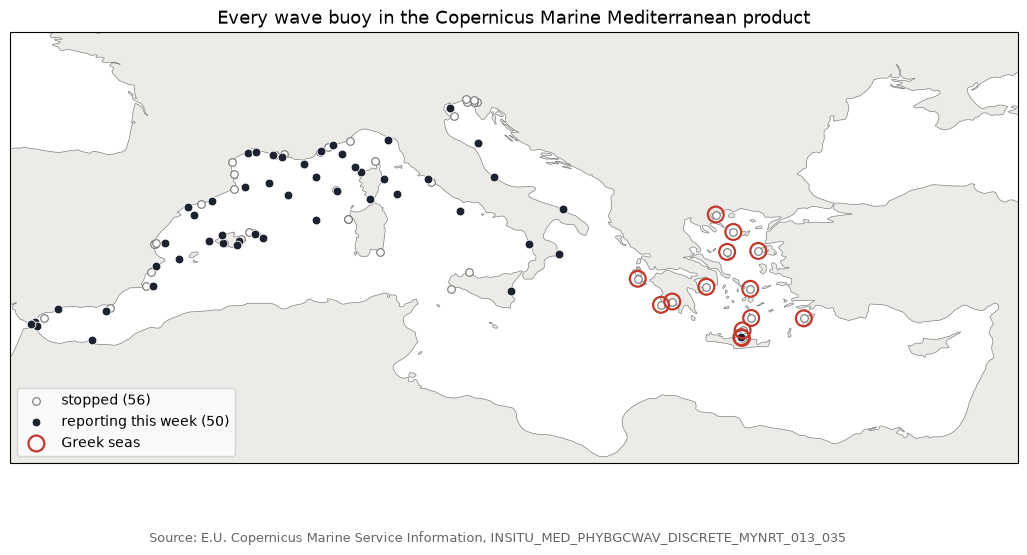

In [4]:
fig = plt.figure(figsize=(13, 6.2))
ax = plt.axes(projection=ccrs.PlateCarree()); ax.set_extent([BOX["west"], BOX["east"], BOX["south"], BOX["north"]])
ax.add_feature(cfeature.LAND.with_scale("50m"), fc="#ecebe7"); ax.coastlines(lw=0.5, color="0.5")
old, now = cat[~cat.reporting], cat[cat.reporting]
ax.scatter(old.lon, old.lat, s=30, fc="white", ec="0.45", lw=0.8, label=f"stopped ({len(old)})", zorder=3)
ax.scatter(now.lon, now.lat, s=40, c=NAVY, ec="white", lw=0.6, label=f"reporting this week ({len(now)})", zorder=4)
g = cat[cat.greek_seas]
ax.scatter(g.lon, g.lat, s=130, fc="none", ec=RED, lw=1.6, label="Greek seas", zorder=5)
ax.legend(loc="lower left", fontsize=10)
ax.set_title("Every wave buoy in the Copernicus Marine Mediterranean product", fontsize=13)
fig.text(0.5, 0.02, "Source: E.U. Copernicus Marine Service Information, INSITU_MED_PHYBGCWAV_DISCRETE_MYNRT_013_035",
         ha="center", fontsize=9, color="0.4")
plt.savefig("buoys_inventory.png", dpi=110, bbox_inches="tight"); plt.show()

Most Greek buoys belong to the **HCMR POSEIDON** network. Only the Heraklion buoy still reaches Copernicus; HCMR
serves the others through its own [POSEIDON API](https://api.poseidon.hcmr.gr/swagger/), which needs a token
(ask `poseidon@hcmr.gr`). The western Mediterranean is well covered by Spain, France and Italy.

In [5]:
# the daily files for the last DAYS days from every buoy still reporting (one netCDF file per buoy per day)
def keys(prefix):
    r = requests.get(S3, params={"prefix": prefix, "delimiter": "/"}, timeout=120).text
    return re.findall(r"<Key>([^<]+)</Key>", r), re.findall(r"<Prefix>([^<]+)</Prefix>", r)

days = sorted(m.group(1) for p in keys(f"{MED}/latest/")[1] if (m := re.search(r"/(\d{8})/$", p)))[-(DAYS + 1):]
buoy = lambda k: (m.group(1) if (m := re.search(r"_TS_MO_(.+)_\d{8}\.nc$", k)) else None)
files = [k for d in days for k in keys(f"{MED}/latest/{d}/")[0] if buoy(k) in set(cat.code)]
os.makedirs("buoys", exist_ok=True)
def download(k):
    path = os.path.join("buoys", k.rsplit("/", 1)[1])
    if not os.path.exists(path):
        open(path, "wb").write(requests.get(f"{S3}/{k}", timeout=120).content)
    return path
with ThreadPoolExecutor(8) as ex: paths = list(ex.map(download, files))
print(f"{len(paths)} files, {days[0]} to {days[-1]}")

358 files, 20261119 to 20261126


In [6]:
# one table: buoy, time and the wave variables, keeping only values the operator flagged good (1) or probably good (2)
NAMES = {"hs": ["VHM0", "VGHS", "VAVH"], "hmax": ["VZMX", "VEMH"], "tp": ["VTPK"], "dir": ["VMDR", "VDIR"]}
def pick(d, names):
    for v in names:
        if v in d:
            x = d[v].values.astype(float)
            q = d[f"{v}_QC"].values if f"{v}_QC" in d else np.ones_like(x)
            x = np.where(np.isin(q, [1, 2]), x, np.nan)
            if x.ndim == 2: x = np.nanmax(np.where(np.isfinite(x), x, -1), axis=1); x[x < 0] = np.nan
            if np.isfinite(x).any(): return x
    return np.full(d.sizes["TIME"], np.nan)

rows = []
for p in paths:
    d = xr.open_dataset(p, decode_timedelta=False)
    df = pd.DataFrame({"time": pd.to_datetime(d.TIME.values), **{k: pick(d, v) for k, v in NAMES.items()}})
    df["id"] = buoy(p)
    rows.append(df)
B = pd.concat(rows).dropna(subset=["hs"]).drop_duplicates(["id", "time"]).sort_values(["id", "time"])
B = B[(B.hs > 0.02) & (B.hs < 15)]
B.loc[B.hmax <= 0, "hmax"] = np.nan                    # a few calm-spell zeros are flagged good: not real
# and a few spikes are flagged good too: drop a value more than 1 m and 50% away from the median of its 5 neighbours
med = B.groupby("id").hs.transform(lambda x: x.rolling(5, center=True, min_periods=3).median())
B = B[~(((B.hs - med).abs() > 1.0) & ((B.hs - med).abs() > 0.5 * med))]
B = B.merge(cat[["code", "operator", "lat", "lon"]], left_on="id", right_on="code").drop(columns="code")
START, END = B.time.max().floor("D") - pd.Timedelta(days=DAYS), B.time.max()
B = B[B.time >= START]
print(f"{B.id.nunique()} buoys, {len(B):,} records, {START:%d %b} to {END:%d %b %Y %H:%M} UTC")
B.groupby("id").agg(operator=("operator", "first"), lat=("lat", "first"), lon=("lon", "first"), records=("hs", "size"),
                    highest_hs=("hs", "max")).sort_values("lon").round(2)

48 buoys, 10,455 records, 19 Nov to 26 Nov 2026 16:00 UTC


,operator,lat,lon,records,highest_hs
id,,,,,
Tarifa-coast-buoy,Puertos del Estado,36.00,-5.59,184,1.00
6101404,Puertos del Estado,36.07,-5.42,184,0.78
Ceuta-coast-buoy,Puertos del Estado,35.90,-5.33,182,0.80
Malaga-coast-buoy,Puertos del Estado,36.64,-4.44,183,0.74
Melilla-coast-buoy,Puertos del Estado,35.32,-2.94,183,0.77
6100198,Puertos del Estado,36.57,-2.34,185,2.70
6100417,Puertos del Estado,37.65,-0.31,185,2.46
VillajoyosaBuoy,AVRAMAR ESPAÑA ACUICULTURA S.L.,38.49,-0.20,369,1.05
6100281,Puertos del Estado,39.52,0.20,185,1.76


## 2 · Where the buoys are, and what one of them measured

The map shows the buoys reporting now. Underneath, everything the `FOCUS` buoy measured over the period:

- **significant wave height**: the typical height of the bigger waves (the average of the highest third). This is
  the number in a marine forecast;
- **highest single wave**: roughly twice the significant height in a storm;
- **peak period**: the time between the most energetic waves. Long periods (8 s and more) are swell that has
  travelled from a distant storm; short ones are local wind sea;
- **direction the waves come from**.

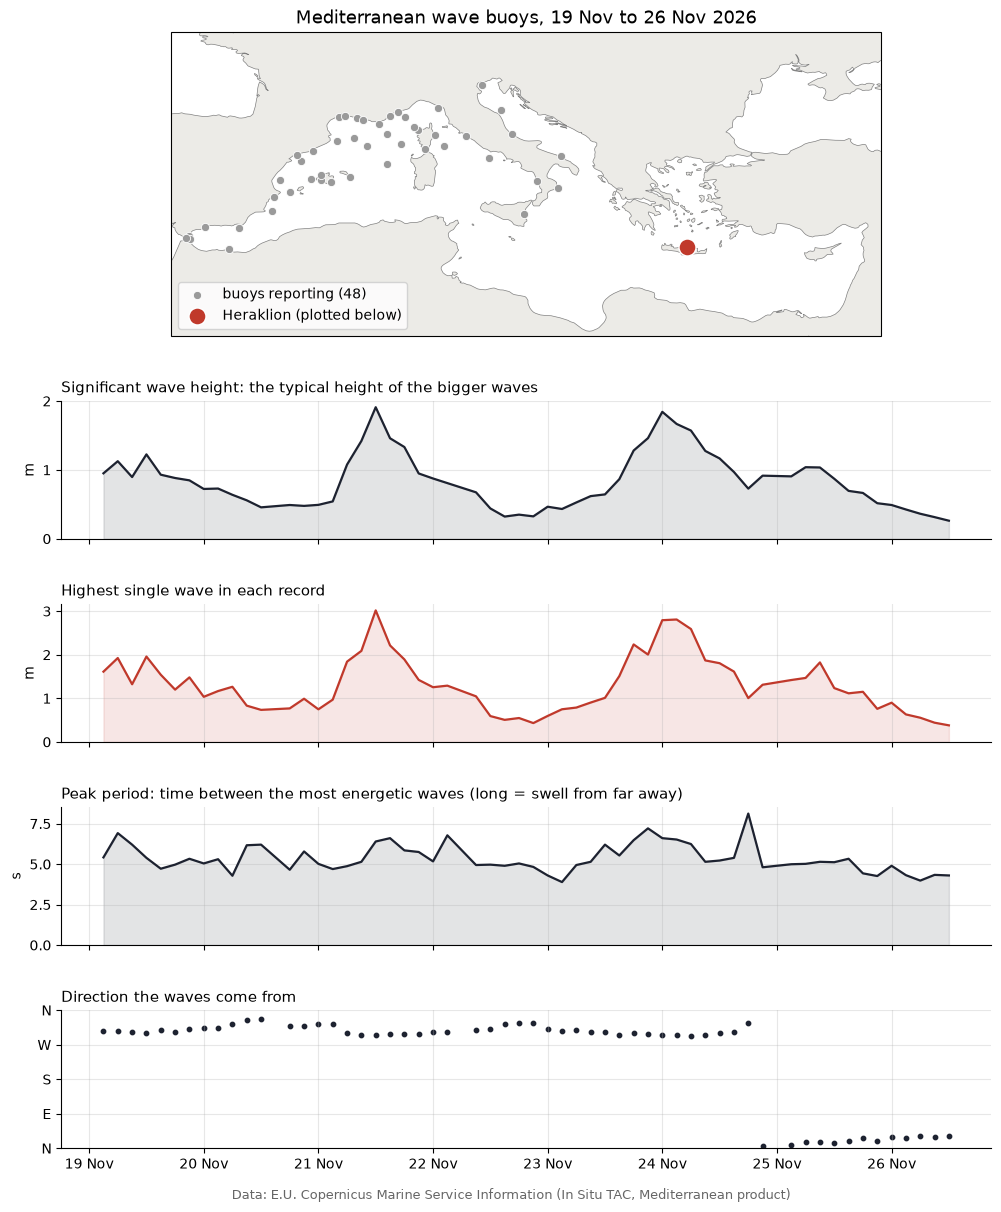

In [7]:
f = B[B.id == FOCUS].set_index("time")
pos = B.groupby("id")[["lat", "lon"]].first()
fig = plt.figure(figsize=(12, 14.5)); gs = fig.add_gridspec(5, 1, height_ratios=[2.2, 1, 1, 1, 1], hspace=0.38)
ax = fig.add_subplot(gs[0], projection=ccrs.PlateCarree()); ax.set_extent([BOX["west"], BOX["east"], BOX["south"], BOX["north"]])
ax.add_feature(cfeature.LAND.with_scale("50m"), fc="#ecebe7"); ax.coastlines(lw=0.5, color="0.5")
ax.scatter(pos.lon, pos.lat, s=35, c=GREY, ec="white", lw=0.6, label=f"buoys reporting ({len(pos)})", zorder=3)
ax.scatter(pos.lon[FOCUS], pos.lat[FOCUS], s=150, c=RED, ec="white", lw=1, label=f"{FOCUS.title()} (plotted below)", zorder=4)
ax.legend(loc="lower left", fontsize=10); ax.set_title(f"Mediterranean wave buoys, {START:%d %b} to {END:%d %b %Y}", fontsize=13)
panels = [("hs", "m", "Significant wave height: the typical height of the bigger waves"),
          ("hmax", "m", "Highest single wave in each record"),
          ("tp", "s", "Peak period: time between the most energetic waves (long = swell from far away)"),
          ("dir", "", "Direction the waves come from")]
axs = []
for k, (v, unit, title) in enumerate(panels):
    a = fig.add_subplot(gs[k + 1], sharex=axs[0] if axs else None); axs.append(a)
    if v == "dir":
        a.scatter(f.index, f[v], s=10, color=NAVY); a.set_ylim(0, 360); a.set_yticks([0, 90, 180, 270, 360], ["N", "E", "S", "W", "N"])
    else:
        c = RED if v == "hmax" else NAVY
        a.plot(f.index, f[v], color=c, lw=1.6); a.fill_between(f.index, 0, f[v], color=c, alpha=0.12); a.set_ylim(0)
    a.set_title(title, loc="left", fontsize=11); a.set_ylabel(unit); a.grid(alpha=0.3); a.spines[["top", "right"]].set_visible(False)
    if k < 3: a.tick_params(labelbottom=False)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%-d %b"))
fig.text(0.5, 0.075, "Data: E.U. Copernicus Marine Service Information (In Situ TAC, Mediterranean product)",
         ha="center", fontsize=9, color="0.4")
plt.savefig("buoys_timeline.png", dpi=110, bbox_inches="tight"); plt.show()

## 3 · The ECMWF wave model at the same hours

ECMWF runs its wave model (HRES-WAM) twice a day and publishes it as open data. Taking the **first 9 hours of each
00 and 12 UTC run** gives one continuous, 3-hourly picture of the sea state, each hour from the freshest forecast.
Older runs come from the cloud mirrors of ECMWF open data (back to 2023).

In [8]:
def get(target, **req):
    """download with ecmwf-opendata, once; a mirror that fails hands over to the next"""
    if os.path.exists(target): return target
    for source in ("google", "ecmwf", "aws"):      # Colab runs on Google Cloud: its mirror is the fastest there
        try: Client(source).retrieve(target=target, **req); return target
        except Exception as err: print(f"   {source}: {type(err).__name__}, trying the next mirror")
    raise RuntimeError(f"no mirror has {req}")

runs = pd.date_range(START.floor("12h"), END, freq="12h")
fields = {}
for run in runs:
    path = get(f"waves_{run:%Y%m%d%H}.grib2", date=run.to_pydatetime(), time=run.hour, stream="wave", type="fc",
               step=[0, 3, 6, 9], param="swh")
    for fl in ekd.from_source("file", path).to_fieldlist():
        if "lat" not in dir():
            lat = np.asarray(fl.geography.latitudes())[:, 0]; lon = ((np.asarray(fl.geography.longitudes())[0] + 180) % 360) - 180
            o = np.argsort(lon); rows_ = (lat >= BOX["south"]) & (lat <= BOX["north"]); cols_ = o[(lon[o] >= BOX["west"]) & (lon[o] <= BOX["east"])]
        v = fl.to_numpy()[rows_][:, cols_]
        fields[run + pd.Timedelta(hours=int(fl.metadata("step")))] = np.where(v > 1e5, np.nan, v)
lat, lon = lat[rows_], lon[cols_]
not_med = ((lon[None, :] < -5.6) & (lat[:, None] > 37)) | ((lon[None, :] < 0) & (lat[:, None] > 43)) | (lon[None, :] > 26.5) & (lat[:, None] > 40.6)   # Biscay, Black Sea
for t in fields: fields[t][not_med] = np.nan
W = xr.DataArray(np.stack([fields[t] for t in sorted(fields)]), dims=("time", "lat", "lon"),
                 coords={"time": sorted(fields), "lat": lat, "lon": lon}, name="swh")
print(f"{len(runs)} runs, {W.sizes['time']} three-hourly fields, {W.time.values[0]} to {W.time.values[-1]}")

16 runs, 64 three-hourly fields, 2026-11-19T00:00:00.000000000 to 2026-11-26T21:00:00.000000000


In [9]:
# the model at each buoy: the nearest sea grid point. The grid is 25 km, so a buoy in a harbour or bay sits in a box that
# is partly land: call a buoy "offshore" when at least 6 of the 9 model points around it are sea
sea = np.isfinite(W.values).all(0)
def nearest_sea(la, lo):
    j, i = int(np.abs(lat - la).argmin()), int(np.abs(lon - lo).argmin())
    cand = [(np.hypot(lat[j + a] - la, (lon[i + b] - lo) * np.cos(np.radians(la))), j + a, i + b)
            for a in (-1, 0, 1) for b in (-1, 0, 1) if 0 <= j + a < len(lat) and 0 <= i + b < len(lon) and sea[j + a, i + b]]
    n_sea = sea[max(j - 1, 0):j + 2, max(i - 1, 0):i + 2].sum()
    return (min(cand)[1:], bool(n_sea >= 6)) if cand else (None, False)

P = []
for bid, d in B.groupby("id"):
    (pt, offshore) = nearest_sea(d.lat.iloc[0], d.lon.iloc[0])
    if pt is None: continue
    model = W[:, pt[0], pt[1]].to_series()
    d = d.set_index("time").sort_index()
    ob = d.hs.reindex(model.index, method="nearest", tolerance=pd.Timedelta("45min"))   # the buoy record nearest each model hour
    P.append(pd.DataFrame({"id": bid, "time": model.index, "model": model.values, "buoy": ob.values, "offshore": offshore}))
P = pd.concat(P).dropna()
P["err"] = P.model - P.buoy
print(f"{P.id.nunique()} buoys paired ({P[P.offshore].id.nunique()} offshore: mostly sea around them in the model)")

48 buoys paired (31 offshore: mostly sea around them in the model)


## 4 · Buoy against model

First the `FOCUS` buoy alone, then the map at its stormiest hour with every buoy as a dot filled with what it
measured, on the same colour scale as the model. **Where a dot disappears into the map, the buoy and the model agree.**

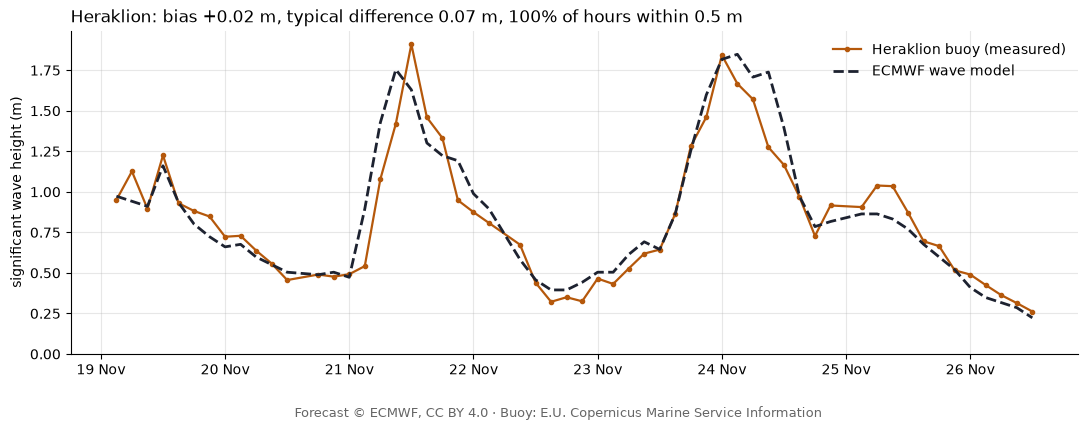

In [10]:
f = B[B.id == FOCUS].set_index("time"); p = P[P.id == FOCUS].set_index("time")
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(f.index, f.hs, "o-", ms=3, color=ORANGE, lw=1.6, label=f"{FOCUS.title()} buoy (measured)")
ax.plot(p.index, p.model, "--", color=NAVY, lw=2, label="ECMWF wave model")
ax.set_ylabel("significant wave height (m)"); ax.set_ylim(0); ax.grid(alpha=0.3); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%-d %b"))
ax.set_title(f"{FOCUS.title()}: bias {p.err.mean():+.2f} m, typical difference {p.err.abs().median():.2f} m, "
             f"{100 * (p.err.abs() <= NEAR).mean():.0f}% of hours within {NEAR} m", loc="left")
fig.text(0.5, -0.04, "Forecast © ECMWF, CC BY 4.0 · Buoy: E.U. Copernicus Marine Service Information", ha="center", fontsize=9, color="0.4")
plt.savefig("buoys_vs_ecmwf_timeline.png", dpi=110, bbox_inches="tight"); plt.show()

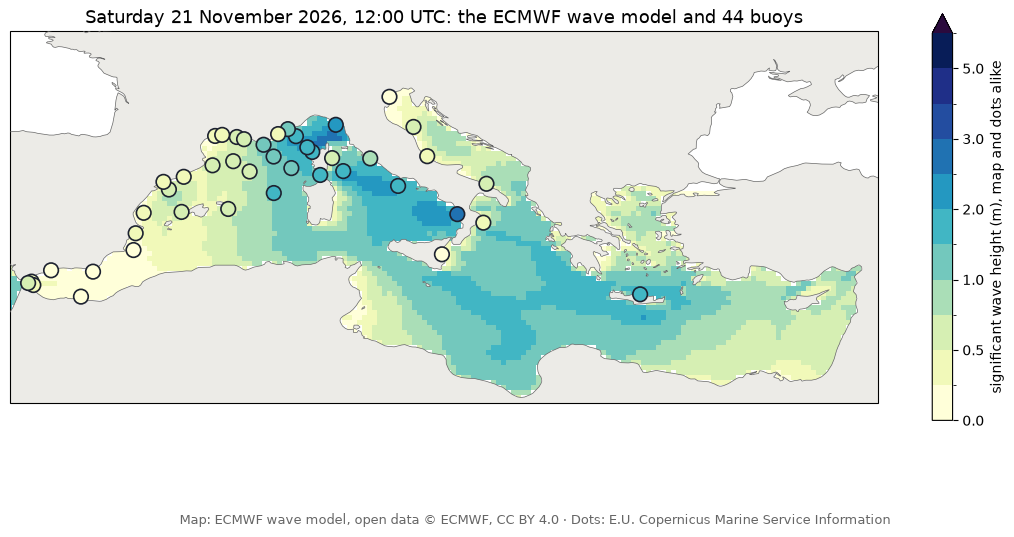

In [11]:
t = p.buoy.idxmax()                                    # the FOCUS buoy's stormiest hour
fig = plt.figure(figsize=(14, 6.6))
ax = plt.axes(projection=ccrs.PlateCarree()); ax.set_extent([BOX["west"], BOX["east"], BOX["south"], BOX["north"]])
m = ax.pcolormesh(W.lon, W.lat, W.sel(time=t), cmap=CMAP, norm=NORM, shading="nearest")
ax.add_feature(cfeature.LAND.with_scale("50m"), fc="#ecebe7", zorder=2); ax.coastlines(lw=0.5, color="0.4", zorder=3)
now = P[P.time == t]
xy = B.groupby("id")[["lon", "lat"]].first().loc[now.id]
ax.scatter(xy.lon, xy.lat, c=now.buoy, cmap=CMAP, norm=NORM, s=110, ec=NAVY, lw=1.2, zorder=5)
plt.colorbar(m, ax=ax, shrink=0.8, extend="max", label="significant wave height (m), map and dots alike")
ax.set_title(f"{pd.Timestamp(t):%A %-d %B %Y, %H:%M} UTC: the ECMWF wave model and {len(now)} buoys", fontsize=13)
fig.text(0.5, 0.03, "Map: ECMWF wave model, open data © ECMWF, CC BY 4.0 · Dots: E.U. Copernicus Marine Service Information",
         ha="center", fontsize=9, color="0.4")
plt.savefig("buoys_vs_ecmwf_map.png", dpi=110, bbox_inches="tight"); plt.show()

## 5 · Every buoy, every hour: how close?

Each dot below is one buoy at one hour. On the diagonal, the model and the buoy agree. Only **offshore** buoys are
scored: a buoy in a harbour or a bay sees sheltered water that a 25 km model box cannot (the table lists them all).

- **bias**: on average, does the model give higher (+) or lower (-) waves than the buoy?
- **RMSE**: the typical size of the difference, weighting big misses more.
- **correlation**: do the ups and downs happen at the same time? (1 = perfectly in step)

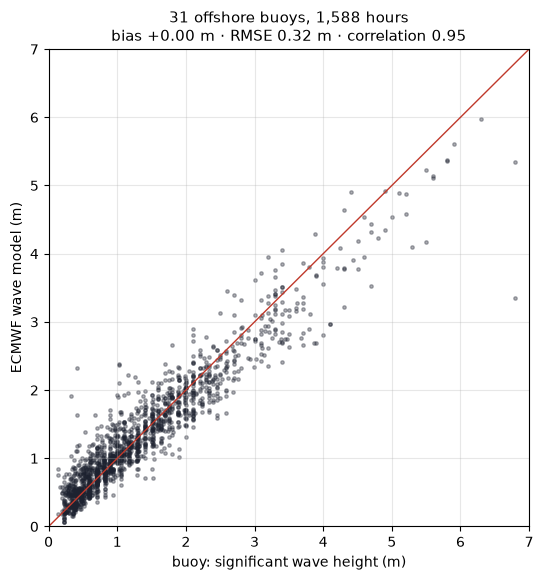

,offshore,hours,buoy mean (m),bias (m),RMSE (m),correlation,operator,lon
id,,,,,,,,
Tarifa-coast-buoy,False,62,0.52,0.10,0.17,0.65,Puertos del Estado,-5.59
6101404,False,62,0.39,0.23,0.27,0.59,Puertos del Estado,-5.42
Ceuta-coast-buoy,True,61,0.35,0.24,0.28,0.55,Puertos del Estado,-5.33
Malaga-coast-buoy,False,62,0.28,0.16,0.21,0.81,Puertos del Estado,-4.44
Melilla-coast-buoy,False,61,0.30,0.27,0.45,0.25,Puertos del Estado,-2.94
6100198,True,62,1.09,-0.04,0.15,0.98,Puertos del Estado,-2.34
6100417,True,62,1.01,-0.19,0.26,0.96,Puertos del Estado,-0.31
VillajoyosaBuoy,False,62,0.44,0.11,0.18,0.90,AVRAMAR ESPAÑA ACUICULTURA S.L.,-0.20
6100281,True,62,0.90,-0.10,0.17,0.95,Puertos del Estado,0.20


In [12]:
o = P[P.offshore]
fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.scatter(o.buoy, o.model, s=6, alpha=0.35, color=NAVY)
hi = np.ceil(max(o.buoy.max(), o.model.max()))
ax.plot([0, hi], [0, hi], color=RED, lw=1); ax.set_xlim(0, hi); ax.set_ylim(0, hi)
ax.set_xlabel("buoy: significant wave height (m)"); ax.set_ylabel("ECMWF wave model (m)"); ax.grid(alpha=0.3)
ax.set_title(f"{o.id.nunique()} offshore buoys, {len(o):,} hours\nbias {o.err.mean():+.2f} m · RMSE {np.sqrt((o.err ** 2).mean()):.2f} m · "
             f"correlation {np.corrcoef(o.buoy, o.model)[0, 1]:.2f}", fontsize=11)
plt.savefig("buoys_vs_ecmwf_scatter.png", dpi=110, bbox_inches="tight"); plt.show()

table = P.groupby("id").apply(lambda d: pd.Series({
    "offshore": d.offshore.iloc[0], "hours": len(d), "buoy mean (m)": d.buoy.mean(), "bias (m)": d.err.mean(),
    "RMSE (m)": np.sqrt((d.err ** 2).mean()), "correlation": np.corrcoef(d.buoy, d.model)[0, 1] if len(d) > 2 else np.nan}))
table = table.join(B.groupby("id")[["operator", "lon"]].first()).sort_values("lon")
table.round(2)

Expect the model to do best on the open sea and in big, well-forecast storms. The usual differences come from:
**sheltered or coastal buoys** (the model sees open sea 25 km away), **short, steep wind seas** in enclosed basins such
as the Aegean, where the wind itself is hard to forecast between the islands, and **small waves**, where a few
centimetres of difference look big in percent but matter little.

## 6 · Your turn 🌍

- **Another buoy:** set `FOCUS` to any code in the section 1 table (e.g. `"6100211"`, off Calabria, or `"6101031"`,
  north-west of Sardinia) and run again.
- **A longer period:** set `DAYS = 30`. Copernicus keeps the last month in `latest/`; older files are in `monthly/`
  and `history/` in the same store.
- **Other variables:** the buoys also measure peak period (`tp`) and direction (`dir`); the ECMWF wave model has the
  same (`pp1d`, `mwd`): add them to the `param` list in section 3.
- **Further ahead:** take steps 24, 48, 72 h instead of 0–9 h and watch the agreement fall with lead time
  (see the [scores notebook](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/hnms_scores.ipynb) for the toolkit).
- **More Greek buoys:** HCMR's POSEIDON network has more buoys around Greece than reach Copernicus today. With a token
  from `poseidon@hcmr.gr`, the [POSEIDON API](https://api.poseidon.hcmr.gr/swagger/) serves them, and every plot here
  works the same.

### Data & licence
**ECMWF open data**, CC BY 4.0: `© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.
**Buoys**: *E.U. Copernicus Marine Service Information*, Mediterranean Sea In Situ Near Real Time Observations,
[doi:10.48670/moi-00044](https://doi.org/10.48670/moi-00044), assembled by HCMR from the operators' data (HCMR, Puertos
del Estado, Météo-France, Cerema, SOCIB, ISPRA, Ifremer and others).

*Not an official ECMWF product: a worked example of open data.*